## <div align="center"> LAB IS794 Deep Learning </div>
## <div align="center"> PROJECT: Exploratory Data Analysis (EDA) Musik Tradisional Indonesia</div>
#### <div align="center"> Odd Semester 2026/2027 </div>
---

In [1]:
import os
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir(os.path.dirname(os.getcwd()))

import datetime
import uuid

In [2]:
import datetime
import uuid

studentName = "Christian Zoe Beru Tena"
studentNIM = "00000108336"
studentClass = "IS794-CL" 

In [3]:
myDate = datetime.datetime.now()
myDevice = str(uuid.uuid1())

print("Name: \t\t{}".format(studentName))
print("NIM: \t\t{}".format(studentNIM))
print("Class: \t\t{}".format(studentClass))
print("Start: \t\t{}".format(myDate))
print("Device ID: \t{}".format(myDevice))

Name: 		Christian Zoe Beru Tena
NIM: 		00000108336
Class: 		IS794-CL
Start: 		2026-10-04 02:13:09.947906
Device ID: 	78c93415-bf5e-11f1-87a1-107c61abb1ed


---

### Enter Lab Code Here:

*(Give the number or each question, according to the module. If the question include a question, answer below your code with text or comment(s).)*

## <div align="center"> Exploratory Data Analysis (EDA) - Dataset Audio Musik Tradisional 38 Provinsi </div>
### Topik Riset: "Perbandingan Model Pre-trained HuBERT dan Wav2Vec 2.0 untuk Klasifikasi Musik Tradisional Berdasarkan Asal Daerah dalam Mendukung Pelestarian Budaya Indonesia" 

### 1. Konfigurasi Environment & Dependensi Audio (FFmpeg Backend Setup)
Dataset yang digunakan terdiri atas rekaman audio berformat `.m4a` (kontainer MPEG-4 dengan kompresi audio Advanced Audio Coding / AAC) yang tersebar di 38 subfolder provinsi Indonesia.

**Kebutuhan Dependensi Pustaka & Backend:**
1. **FFmpeg & FFprobe**: Pustaka audio modern seperti `torchaudio` dan `librosa` (melalui engine `audioread`) memerlukan framework multimedia **FFmpeg** pada tingkat sistem operasi untuk membedah kontainer `.m4a` dan mendekode bitstream AAC ke representasi uncompressed floating-point PCM waveform.
2. **Pustaka Analisis Data & Audio**: `torch`, `torchaudio`, `librosa`, `soundfile`, `pandas`, `numpy`, `matplotlib`, dan `seaborn`.

Pada cell kode di bawah ini, path binary FFmpeg didaftarkan ke variabel lingkungan sistem (`os.environ["PATH"]`), pustaka utama diimpor, dan ketersediaan hardware akselerasi (GPU CUDA) serta dependensi diverifikasi.

In [4]:
# 1. Konfigurasi path FFmpeg ke dalam PATH lingkungan eksekusi
import os
import sys

# Mendaftarkan direktori binary FFmpeg dari environment conda
ffmpeg_paths = [
    r"C:\Users\chris\anaconda3\envs\deeplearning\Library\bin",
    r"C:\Users\chris\anaconda3\Library\bin"
]
for p in ffmpeg_paths:
    if os.path.isdir(p) and p not in os.environ["PATH"]:
        os.environ["PATH"] = p + ";" + os.environ["PATH"]

# 2. Import pustaka analisis data, pemrosesan audio, dan visualisasi
import glob
import json
import time
import subprocess
import warnings
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torchaudio
import librosa
import soundfile as sf

# Konfigurasi style grafik visualisasi
warnings.filterwarnings("ignore")
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["figure.dpi"] = 100

# Verifikasi dependensi dan hardware akselerasi
print("=" * 65)
print("VERIFIKASI DEPENDENSI ENVIRONMENT & HARDWARE")
print("=" * 65)
print(f"Python Version       : {sys.version.split()[0]}")
print(f"PyTorch Version      : {torch.__version__}")
print(f"Torchaudio Version   : {torchaudio.__version__}")
print(f"Librosa Version      : {librosa.__version__}")
print(f"Pandas Version       : {pd.__version__}")
print(f"CUDA Available       : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU Device Name      : {torch.cuda.get_device_name(0)}")

# Verifikasi binary FFmpeg
ffmpeg_found = False
for p in ffmpeg_paths:
    if os.path.isfile(os.path.join(p, "ffmpeg.exe")):
        print(f"FFmpeg Binary Path   : {os.path.join(p, 'ffmpeg.exe')} [AKTIF]")
        ffmpeg_found = True
        break
if not ffmpeg_found:
    print("Peringatan: FFmpeg binary tidak ditemukan di path default. Pastikan FFmpeg terpasang.")
print("=" * 65)

VERIFIKASI DEPENDENSI ENVIRONMENT & HARDWARE
Python Version       : 3.10.13
PyTorch Version      : 2.5.1+cu121
Torchaudio Version   : 2.5.1+cu121
Librosa Version      : 0.11.0
Pandas Version       : 2.3.3
CUDA Available       : True
GPU Device Name      : NVIDIA GeForce RTX 2050
FFmpeg Binary Path   : C:\Users\chris\anaconda3\envs\deeplearning\Library\bin\ffmpeg.exe [AKTIF]


### 2. Inventaris Dataset Musik Tradisional (File Count, Durasi, dan Tabel Ringkasan DataFrame)
Pada tahap ini, kita memindai direktori `data/` yang memuat seluruh **38 subfolder provinsi** di Indonesia. Untuk setiap berkas audio `.m4a`, kita mengekstrak informasi metadata teknis:
- **Provinsi**: Label kelas asal daerah (nama subdirektori).
- **Nama File**: Judul dan identifikasi berkas rekaman lagu.
- **Ukuran File**: Ukuran berkas dalam Kilobytes (KB).
- **Durasi**: Panjang rekaman audio dalam detik.
- **Sample Rate**: Frekuensi pencuplikan sinyal suara asli (Hz).
- **Jumlah Saluran (Channels)**: Konfigurasi mono (1 channel) atau stereo (2 channel).
- **Codec**: Format kompresi audio (AAC).

Proses ekstraksi metadata dilakukan secara multi-threading menggunakan `ThreadPoolExecutor` dan `ffprobe` agar sangat cepat (~7-8 detik untuk 855 berkas). Selanjutnya, dibuat tabel ringkasan teragregasi yang mencakup seluruh 38 provinsi di Indonesia (termasuk deteksi provinsi dengan folder kosong).

In [5]:
# Lokasi direktori dataset utama
DATA_DIR = "data"
ffprobe_bin = r"C:\Users\chris\anaconda3\envs\deeplearning\Library\bin\ffprobe.exe"

# Deteksi seluruh 38 subfolder provinsi yang ada di direktori data
all_provinces = sorted([d for d in os.listdir(DATA_DIR) if os.path.isdir(os.path.join(DATA_DIR, d))])
print(f"Ditemukan total {len(all_provinces)} subdirektori provinsi dalam folder '{DATA_DIR}'.")

# Cari seluruh file rekaman audio .m4a dalam subdirektori data
audio_files = glob.glob(os.path.join(DATA_DIR, "*", "*.m4a"))
print(f"Ditemukan total {len(audio_files)} berkas audio .m4a di dalam dataset.\n")

def extract_audio_metadata(file_path):
    """Mengekstrak metadata teknis audio menggunakan ffprobe JSON output."""
    rel_path = os.path.relpath(file_path, DATA_DIR)
    province = os.path.dirname(rel_path)
    file_name = os.path.basename(rel_path)
    size_kb = os.path.getsize(file_path) / 1024.0
    
    try:
        cmd = [
            ffprobe_bin, "-v", "error",
            "-show_entries", "format=duration,size,bit_rate:stream=sample_rate,channels,codec_name",
            "-of", "json", file_path
        ]
        res = subprocess.run(cmd, stdout=subprocess.PIPE, stderr=subprocess.PIPE, text=True, timeout=10)
        info = json.loads(res.stdout)
        
        streams = info.get("streams", [])
        audio_stream = next((s for s in streams if "sample_rate" in s or "channels" in s), {})
        
        duration = float(info.get("format", {}).get("duration", 0.0))
        sr = int(audio_stream.get("sample_rate", 0))
        channels = int(audio_stream.get("channels", 0))
        codec = audio_stream.get("codec_name", "unknown")
        
        status = "Valid" if (duration > 0 and sr > 0) else "Corrupt"
        return {
            "file_path": file_path,
            "provinsi": province,
            "nama_file": file_name,
            "ukuran_kb": round(size_kb, 2),
            "durasi_detik": round(duration, 2),
            "sample_rate": sr,
            "channels": channels,
            "codec": codec,
            "status": status
        }
    except Exception as e:
        return {
            "file_path": file_path,
            "provinsi": province,
            "nama_file": file_name,
            "ukuran_kb": round(size_kb, 2),
            "durasi_detik": 0.0,
            "sample_rate": 0,
            "channels": 0,
            "codec": "error",
            "status": "Corrupt"
        }

# Jalankan ekstraksi metadata secara paralel (multi-threading)
t_start = time.time()
with ThreadPoolExecutor(max_workers=8) as executor:
    metadata_list = list(executor.map(extract_audio_metadata, audio_files))
t_end = time.time()

# Buat DataFrame metadata audio
df_metadata = pd.DataFrame(metadata_list)
print(f"Pemindaian metadata 855 berkas selesai dalam {t_end - t_start:.2f} detik.")
print(f"Dimensi DataFrame Metadata: {df_metadata.shape[0]} baris, {df_metadata.shape[1]} kolom.\n")

# Buat tabel ringkasan inventaris per provinsi dari data file
df_prov_agg = df_metadata.groupby("provinsi").agg(
    Jumlah_File=("file_path", "count"),
    Total_Durasi_Menit=("durasi_detik", lambda x: round(x.sum() / 60.0, 2)),
    Total_Durasi_Jam=("durasi_detik", lambda x: round(x.sum() / 3600.0, 2)),
    Rata_Rata_Durasi_Detik=("durasi_detik", lambda x: round(x.mean(), 2)),
    Min_Durasi_Detik=("durasi_detik", "min"),
    Max_Durasi_Detik=("durasi_detik", "max")
).reset_index()

# Gabungkan dengan seluruh 38 provinsi agar provinsi kosong tetap tercatat
df_all_prov = pd.DataFrame({"provinsi": all_provinces})
df_provinsi_summary = pd.merge(df_all_prov, df_prov_agg, on="provinsi", how="left")
df_provinsi_summary["Jumlah_File"] = df_provinsi_summary["Jumlah_File"].fillna(0).astype(int)
df_provinsi_summary["Total_Durasi_Menit"] = df_provinsi_summary["Total_Durasi_Menit"].fillna(0.0)
df_provinsi_summary["Total_Durasi_Jam"] = df_provinsi_summary["Total_Durasi_Jam"].fillna(0.0)
df_provinsi_summary["Rata_Rata_Durasi_Detik"] = df_provinsi_summary["Rata_Rata_Durasi_Detik"].fillna(0.0)
df_provinsi_summary["Min_Durasi_Detik"] = df_provinsi_summary["Min_Durasi_Detik"].fillna(0.0)
df_provinsi_summary["Max_Durasi_Detik"] = df_provinsi_summary["Max_Durasi_Detik"].fillna(0.0)

# Urutkan berdasarkan jumlah file secara descending
df_provinsi_summary = df_provinsi_summary.sort_values(by="Jumlah_File", ascending=False).reset_index(drop=True)

# Tampilkan ringkasan inventaris
print("=" * 90)
print("TABEL RINGKASAN INVENTARIS DATASET AUDIO PER PROVINSI (TOP 10)")
print("=" * 90)
print(df_provinsi_summary.head(10).to_string(index=False))

print("\n" + "=" * 90)
print("TABEL RINGKASAN INVENTARIS DATASET AUDIO PER PROVINSI (BOTTOM 10)")
print("=" * 90)
print(df_provinsi_summary.tail(10).to_string(index=False))

print("\n" + "=" * 90)
print("STATISTIK AKUMULASI KESELURUHAN DATASET:")
print(f"Total Sampel Audio     : {len(df_metadata)} file")
print(f"Total Subdirektori     : {len(all_provinces)} provinsi")
print(f"Provinsi Berisi Audio  : {df_metadata['provinsi'].nunique()} provinsi")
print(f"Provinsi Folder Kosong : {len(all_provinces) - df_metadata['provinsi'].nunique()} provinsi (Papua_Pegunungan = 0 berkas)")
print(f"Total Durasi Audio     : {df_provinsi_summary['Total_Durasi_Menit'].sum():,.2f} menit ({df_provinsi_summary['Total_Durasi_Jam'].sum():.2f} jam)")
print(f"Total Ukuran Berkas    : {df_metadata['ukuran_kb'].sum() / 1024.0:,.2f} MB ({df_metadata['ukuran_kb'].sum() / (1024.0**2):.2f} GB)")
print("=" * 90)

Ditemukan total 38 subdirektori provinsi dalam folder 'data'.
Ditemukan total 855 berkas audio .m4a di dalam dataset.



Pemindaian metadata 855 berkas selesai dalam 8.76 detik.
Dimensi DataFrame Metadata: 855 baris, 9 kolom.

TABEL RINGKASAN INVENTARIS DATASET AUDIO PER PROVINSI (TOP 10)
           provinsi  Jumlah_File  Total_Durasi_Menit  Total_Durasi_Jam  Rata_Rata_Durasi_Detik  Min_Durasi_Detik  Max_Durasi_Detik
Nusa_Tenggara_Timur           78              370.63              6.18                  285.10             52.01            850.02
         Jawa_Barat           57              256.48              4.27                  269.97             28.01           1358.02
     Sumatera_Barat           55              276.81              4.61                  301.98             46.02           1342.00
   Sulawesi_Selatan           55              290.39              4.84                  316.79             56.00            702.02
     Sumatera_Utara           50              210.27              3.50                  252.32            110.00            484.01
   Kalimantan_Barat           49             

### 3. Analisis Distribusi Kelas & Deteksi Ketimpangan Data (Class Imbalance)
Distribusi jumlah sampel per kelas merupakan faktor kritikal dalam pemodelan Machine Learning dan Deep Learning. Jika terjadi ketimpangan ekstrem (*extreme class imbalance*), model cenderung mengalami bias terhadap kelas mayoritas dan gagal mengenali pola akustik pada kelas minoritas (*long-tail classes*).

Pada tahap ini, kita:
1. Memvisualisasikan jumlah file per provinsi menggunakan **Horizontal Bar Chart** beresolusi tinggi, diurutkan dari yang terbanyak hingga tersedikit.
2. Menandai kelas dengan data yang sangat minim (**< 5 file**) dengan warna kontras (merah/oranye) dan garis ambang batas (*threshold line*).
3. Menghitung rasio ketimpangan (*imbalance ratio*) antara kelas mayoritas dan minoritas.

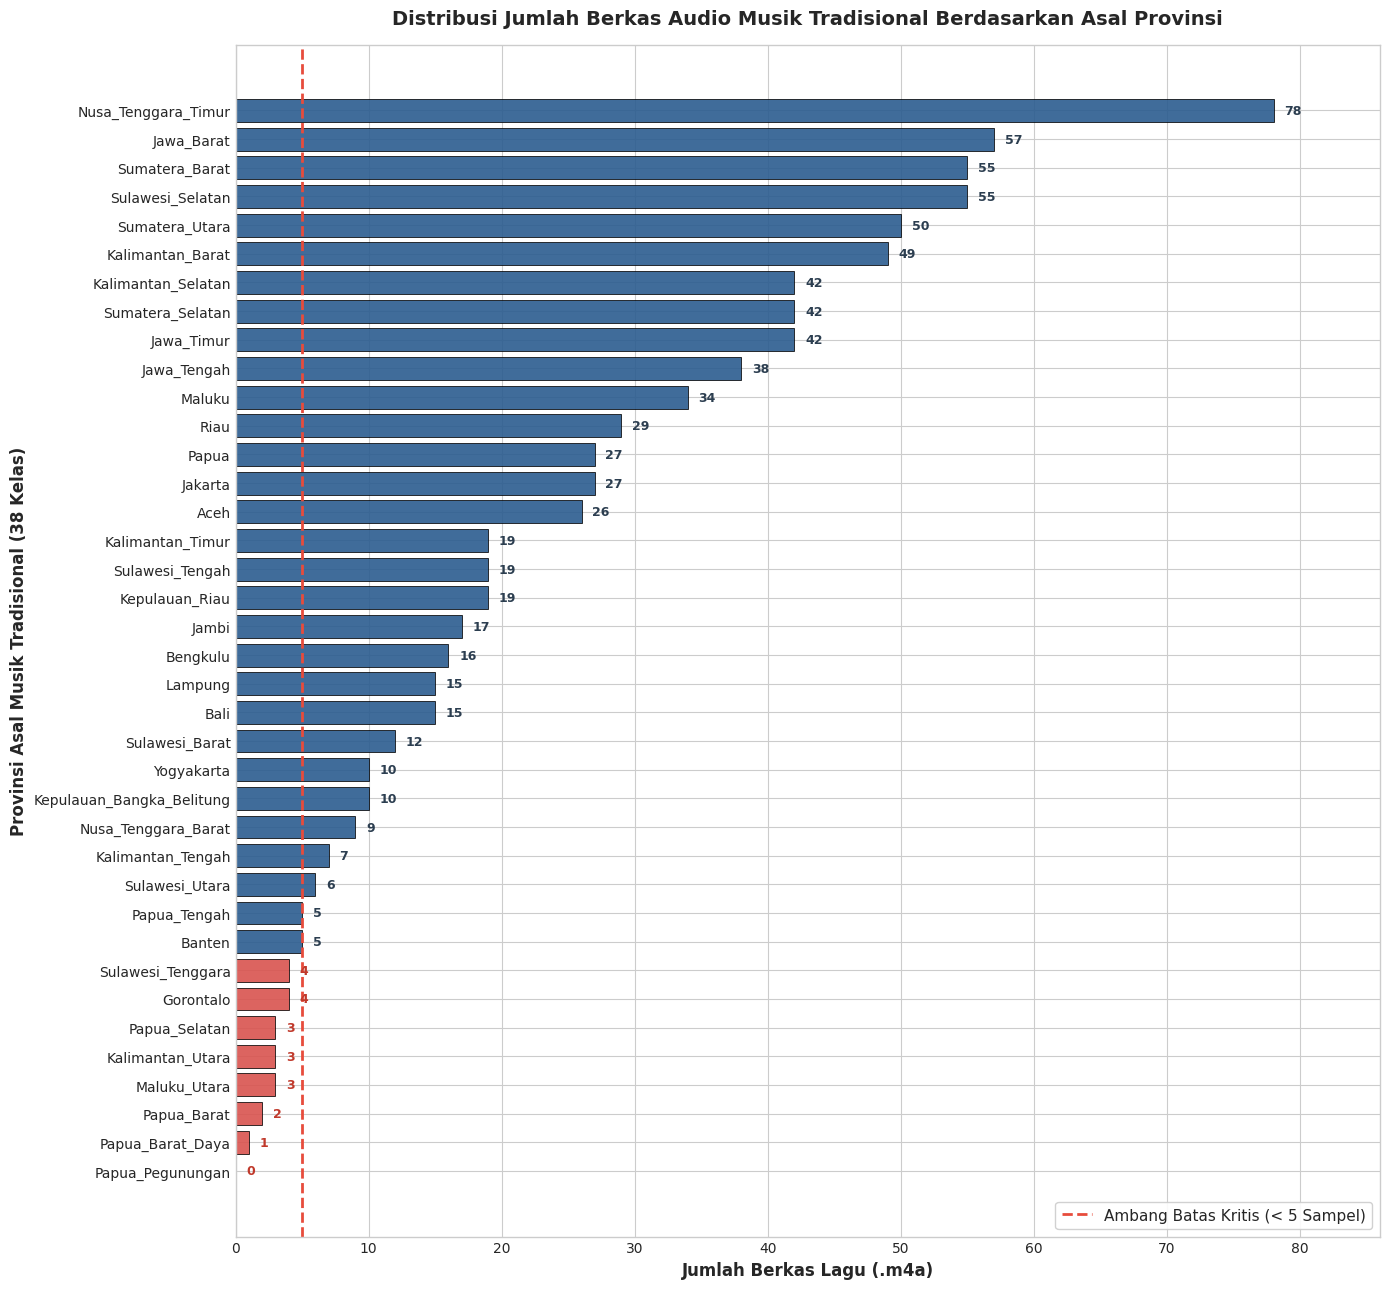

ANALISIS KETIMPANGAN KELAS (CLASS IMBALANCE):
Kelas Terbanyak (Mayoritas) : Nusa_Tenggara_Timur (78 berkas)
Kelas Tersedikit (Aktif)    : Papua_Barat_Daya (1 berkas)
Kelas Kosong (0 berkas)     : Papua_Pegunungan (0 berkas)
Rasio Ketimpangan (Imbalance Ratio Aktif): 78.0 : 1
Jumlah Provinsi Kritis (< 5 berkas): 8 dari 38 provinsi (21.1%)
--------------------------------------------------------------------------------
Daftar 8 Provinsi dengan Sampel Sangat Sedikit (< 5 Berkas):
         provinsi  Jumlah_File  Total_Durasi_Menit
Sulawesi_Tenggara            4               16.32
        Gorontalo            4               16.97
    Papua_Selatan            3               12.78
 Kalimantan_Utara            3                7.74
     Maluku_Utara            3               15.53
      Papua_Barat            2                8.20
 Papua_Barat_Daya            1                4.24
 Papua_Pegunungan            0                0.00


In [6]:
# Identifikasi kelas dengan sampel sangat minim (< 5 file)
THRESHOLD_MIN_SAMPLES = 5
df_provinsi_summary['is_minority'] = df_provinsi_summary['Jumlah_File'] < THRESHOLD_MIN_SAMPLES

minority_classes = df_provinsi_summary[df_provinsi_summary['is_minority']]
majority_max = df_provinsi_summary['Jumlah_File'].max()
minority_min = df_provinsi_summary[df_provinsi_summary['Jumlah_File'] > 0]['Jumlah_File'].min()
imbalance_ratio = majority_max / minority_min

# Visualisasi Distribusi Kelas
plt.figure(figsize=(14, 13))

# Tetapkan palet warna: merah untuk < 5 file, biru/teal untuk >= 5 file
bar_colors = ['#d9534f' if is_min else '#2b5c8f' for is_min in df_provinsi_summary['is_minority']]

bars = plt.barh(
    df_provinsi_summary['provinsi'],
    df_provinsi_summary['Jumlah_File'],
    color=bar_colors,
    edgecolor='black',
    linewidth=0.6,
    alpha=0.9
)

# Balik urutan sumbu Y agar provinsi terbanyak ada di posisi paling atas
plt.gca().invert_yaxis()

# Tambahkan label angka di ujung setiap batang
for bar in bars:
    w = bar.get_width()
    plt.text(
        w + 0.8,
        bar.get_y() + bar.get_height() / 2,
        f"{int(w)}",
        ha='left',
        va='center',
        fontsize=9,
        fontweight='bold',
        color='#c0392b' if w < THRESHOLD_MIN_SAMPLES else '#2c3e50'
    )

# Garis ambang batas batas sampel kritis (< 5 berkas)
plt.axvline(
    x=THRESHOLD_MIN_SAMPLES,
    color='#e74c3c',
    linestyle='--',
    linewidth=2,
    label=f'Ambang Batas Kritis (< {THRESHOLD_MIN_SAMPLES} Sampel)'
)

plt.title('Distribusi Jumlah Berkas Audio Musik Tradisional Berdasarkan Asal Provinsi', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Jumlah Berkas Lagu (.m4a)', fontsize=12, fontweight='bold')
plt.ylabel('Provinsi Asal Musik Tradisional (38 Kelas)', fontsize=12, fontweight='bold')
plt.xlim(0, majority_max + 8)
plt.legend(loc='lower right', fontsize=11, frameon=True, facecolor='white', framealpha=0.9)
plt.tight_layout()
plt.show()

# Cetak Analisis Kuantitatif Ketimpangan Kelas
print("=" * 80)
print("ANALISIS KETIMPANGAN KELAS (CLASS IMBALANCE):")
print("=" * 80)
print(f"Kelas Terbanyak (Mayoritas) : {df_provinsi_summary.iloc[0]['provinsi']} ({majority_max} berkas)")
print(f"Kelas Tersedikit (Aktif)    : Papua_Barat_Daya ({minority_min} berkas)")
print(f"Kelas Kosong (0 berkas)     : Papua_Pegunungan (0 berkas)")
print(f"Rasio Ketimpangan (Imbalance Ratio Aktif): {imbalance_ratio:.1f} : 1")
print(f"Jumlah Provinsi Kritis (< {THRESHOLD_MIN_SAMPLES} berkas): {len(minority_classes)} dari 38 provinsi ({len(minority_classes)/38*100:.1f}%)")
print("-" * 80)
print("Daftar 8 Provinsi dengan Sampel Sangat Sedikit (< 5 Berkas):")
print(minority_classes[['provinsi', 'Jumlah_File', 'Total_Durasi_Menit']].to_string(index=False))
print("=" * 80)

### 4. Analisis Properti Sinyal Audio dan Pemeriksaan Integritas Berkas
Pemeriksaan karakteristik fisik gelombang audio sangat penting untuk memvalidasi kelayakan data latih, mencakup:
1. **Audit Integritas Berkas**: Mengidentifikasi apakah ada berkas yang rusak (*corrupted*), kosong (0-byte), atau gagal diurai oleh decoder.
2. **Distribusi Sampling Rate (Frekuensi Pencuplikan)**: Mengetahui seberapa bervariasi resolusi frekuensi berkas sumber (misal 44.1 kHz vs 48 kHz).
3. **Konfigurasi Channel**: Memeriksa saluran audio (Mono vs Stereo).
4. **Analisis Statistik Durasi**: Menghitung metrik ringkasan durasi (Min, Max, Mean, Median, IQR, Skewness) dan memvisualisasikan persebarannya via Histogram, kurva KDE (*Kernel Density Estimation*), serta Boxplot untuk mendeteksi pencilan (*outliers*) lagu berdurasi sangat panjang.

STATUS INTEGRITAS BERKAS AUDIO DALAM DATASET:
status
Valid    855
HASIL AUDIT: 100% berkas audio (855/855) VALID dan dapat di-load sempurna!


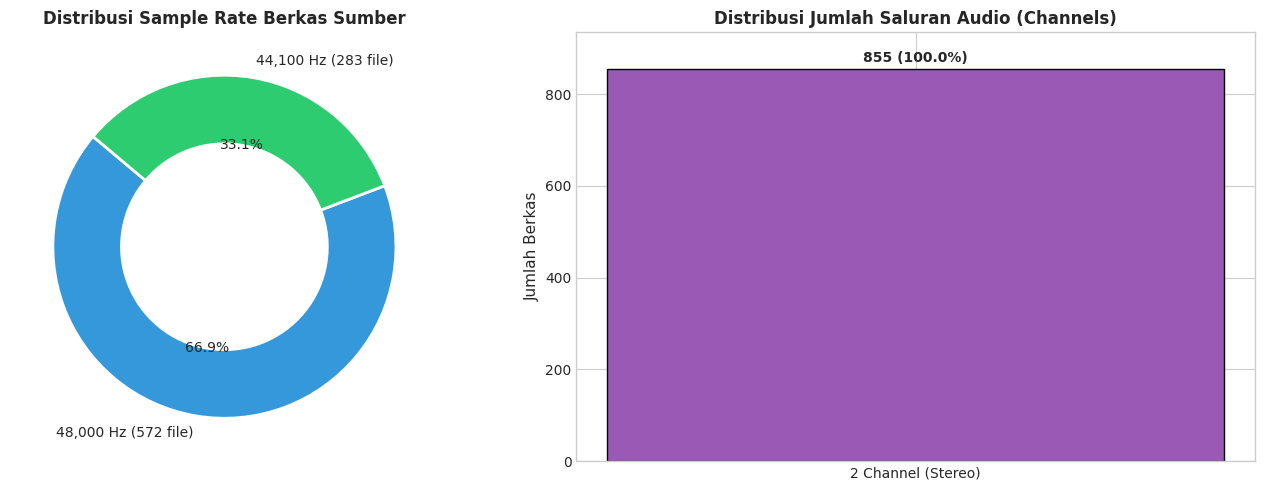


STATISTIK DESKRIPTIF DURASI AUDIO (DETIK):
----------------------------------------------------------------------
Jumlah Sampel      : 855
Durasi Minimum     : 28.01 detik (0.47 menit)
Kuartil 1 (Q1)     : 182.79 detik (3.05 menit)
Median (Q2)        : 241.75 detik (4.03 menit)
Rata-rata (Mean)   : 257.95 detik (4.30 menit)
Kuartil 3 (Q3)     : 298.05 detik (4.97 menit)
Durasi Maksimum    : 1854.02 detik (30.90 menit)
Standar Deviasi    : 135.39 detik
Skewness (Kemiringan): 4.09 (Positively skewed / ekor ke kanan)


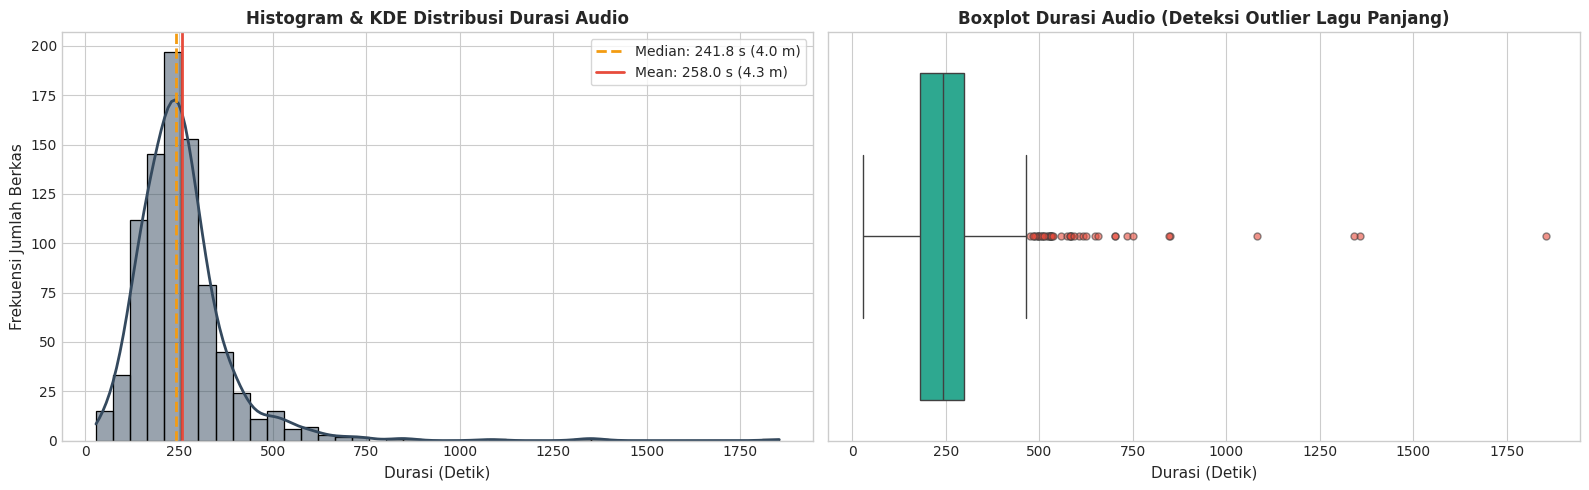

In [7]:
# 1. Pengecekan Integritas Berkas Audio
status_counts = df_metadata["status"].value_counts()
print("=" * 70)
print("STATUS INTEGRITAS BERKAS AUDIO DALAM DATASET:")
print(status_counts.to_string())
if (df_metadata["status"] == "Valid").all():
    print("HASIL AUDIT: 100% berkas audio (855/855) VALID dan dapat di-load sempurna!")
else:
    corrupt_files = df_metadata[df_metadata["status"] != "Valid"]
    print(f"PERINGATAN: Ditemukan {len(corrupt_files)} berkas korup!")
print("=" * 70)

# 2. Visualisasi Properti Teknis: Sample Rate & Channel
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Donut chart Sample Rate
sr_counts = df_metadata["sample_rate"].value_counts()
colors_sr = ["#3498db", "#2ecc71"]
axes[0].pie(
    sr_counts,
    labels=[f"{sr:,} Hz ({count} file)" for sr, count in sr_counts.items()],
    autopct='%1.1f%%',
    startangle=140,
    colors=colors_sr,
    wedgeprops=dict(width=0.4, edgecolor='white', linewidth=2)
)
axes[0].set_title("Distribusi Sample Rate Berkas Sumber", fontsize=12, fontweight="bold")

# Bar chart Channels
ch_counts = df_metadata["channels"].value_counts()
axes[1].bar(
    [f"{ch} Channel (Stereo)" if ch == 2 else f"{ch} Channel (Mono)" for ch in ch_counts.index],
    ch_counts.values,
    color="#9b59b6",
    edgecolor="black",
    width=0.4
)
axes[1].set_title("Distribusi Jumlah Saluran Audio (Channels)", fontsize=12, fontweight="bold")
axes[1].set_ylabel("Jumlah Berkas", fontsize=11)
for i, v in enumerate(ch_counts.values):
    axes[1].text(i, v + 15, f"{v} ({v/len(df_metadata)*100:.1f}%)", ha='center', fontweight='bold')
axes[1].set_ylim(0, len(df_metadata) + 80)

plt.tight_layout()
plt.show()

# 3. Analisis Statistik Durasi Berkas Audio
durasi = df_metadata["durasi_detik"]
print("\n" + "=" * 70)
print("STATISTIK DESKRIPTIF DURASI AUDIO (DETIK):")
print("-" * 70)
print(f"Jumlah Sampel      : {len(durasi)}")
print(f"Durasi Minimum     : {durasi.min():.2f} detik ({durasi.min()/60:.2f} menit)")
print(f"Kuartil 1 (Q1)     : {durasi.quantile(0.25):.2f} detik ({durasi.quantile(0.25)/60:.2f} menit)")
print(f"Median (Q2)        : {durasi.median():.2f} detik ({durasi.median()/60:.2f} menit)")
print(f"Rata-rata (Mean)   : {durasi.mean():.2f} detik ({durasi.mean()/60:.2f} menit)")
print(f"Kuartil 3 (Q3)     : {durasi.quantile(0.75):.2f} detik ({durasi.quantile(0.75)/60:.2f} menit)")
print(f"Durasi Maksimum    : {durasi.max():.2f} detik ({durasi.max()/60:.2f} menit)")
print(f"Standar Deviasi    : {durasi.std():.2f} detik")
print(f"Skewness (Kemiringan): {durasi.skew():.2f} (Positively skewed / ekor ke kanan)")
print("=" * 70)

# 4. Visualisasi Distribusi Durasi (Histogram + KDE & Boxplot)
fig, (ax_hist, ax_box) = plt.subplots(1, 2, figsize=(16, 5))

# Histogram & KDE
sns.histplot(durasi, kde=True, ax=ax_hist, color="#34495e", bins=40, line_kws={"linewidth": 2, "color": "#e74c3c"})
ax_hist.axvline(durasi.median(), color='#f39c12', linestyle='--', linewidth=2, label=f'Median: {durasi.median():.1f} s ({durasi.median()/60:.1f} m)')
ax_hist.axvline(durasi.mean(), color='#e74c3c', linestyle='-', linewidth=2, label=f'Mean: {durasi.mean():.1f} s ({durasi.mean()/60:.1f} m)')
ax_hist.set_title("Histogram & KDE Distribusi Durasi Audio", fontsize=12, fontweight="bold")
ax_hist.set_xlabel("Durasi (Detik)", fontsize=11)
ax_hist.set_ylabel("Frekuensi Jumlah Berkas", fontsize=11)
ax_hist.legend(loc='upper right', frameon=True)

# Boxplot Durasi untuk melihat pencilan (outliers)
sns.boxplot(x=durasi, ax=ax_box, color="#1abc9c", flierprops=dict(marker='o', markersize=5, markerfacecolor='#e74c3c', alpha=0.6))
ax_box.set_title("Boxplot Durasi Audio (Deteksi Outlier Lagu Panjang)", fontsize=12, fontweight="bold")
ax_box.set_xlabel("Durasi (Detik)", fontsize=11)

plt.tight_layout()
plt.show()

### 5. Visualisasi Sampel Audio Lintas Wilayah Nusantara (Waveform, Mel-Spectrogram, & MFCC)
Untuk menganalisis variasi sinyal suara secara mendalam, kita memvisualisasikan 4 rekaman musik tradisional representatif dari zona geografis dan budaya yang berbeda:
1. **Aceh (Wilayah Barat / Sumatera)**: Lagu *Saleum* (`data/Aceh/10_Saleum.m4a`) - melodi vokal Melayu/Aceh dengan ritme rebana bertempo sedang.
2. **Jawa Barat (Wilayah Jawa)**: Lagu *Es Lilin* (`data/Jawa_Barat/233_Es_Lilin.m4a`) - gamelan degung Sunda dengan tangga nada pentatonis (salendro/pelog) yang mengalir halus.
3. **Nusa Tenggara Timur (Wilayah Kepulauan Sunda Kecil)**: Lagu *Bolelebo* (`data/Nusa_Tenggara_Timur/355_Bolelebo.m4a`) - petikan dawai sasando / instrumen senar bertempo lembut dengan vibrato vokal khas.
4. **Papua (Wilayah Timur / Melanesia)**: Lagu *Yamko Rambe Yamko* (`data/Papua/579_Yamko_Rambe_Yamko.m4a`) - tabuhan perkusif ritmis tifa bertempo cepat dan dinamika vokal mars heroisme yang lantang.

Setiap lagu dianalisis pada cuplikan 15 detik pertama dalam 3 representasi:
- **Waveform (Domain Waktu)**: Memperlihatkan amplitudo sinyal terhadap waktu.
- **Log Mel-Spectrogram (Domain Frekuensi Terbobot Mel)**: Memetakan intensitas spektral (dalam dB) pada skala Mel yang merefleksikan sensitivitas pendengaran manusia.
- **MFCC (Mel-Frequency Cepstral Coefficients)**: Ekstraksi 13 koefisien yang merepresentasikan amplop spektral dan timbre/warna suara instrumen.

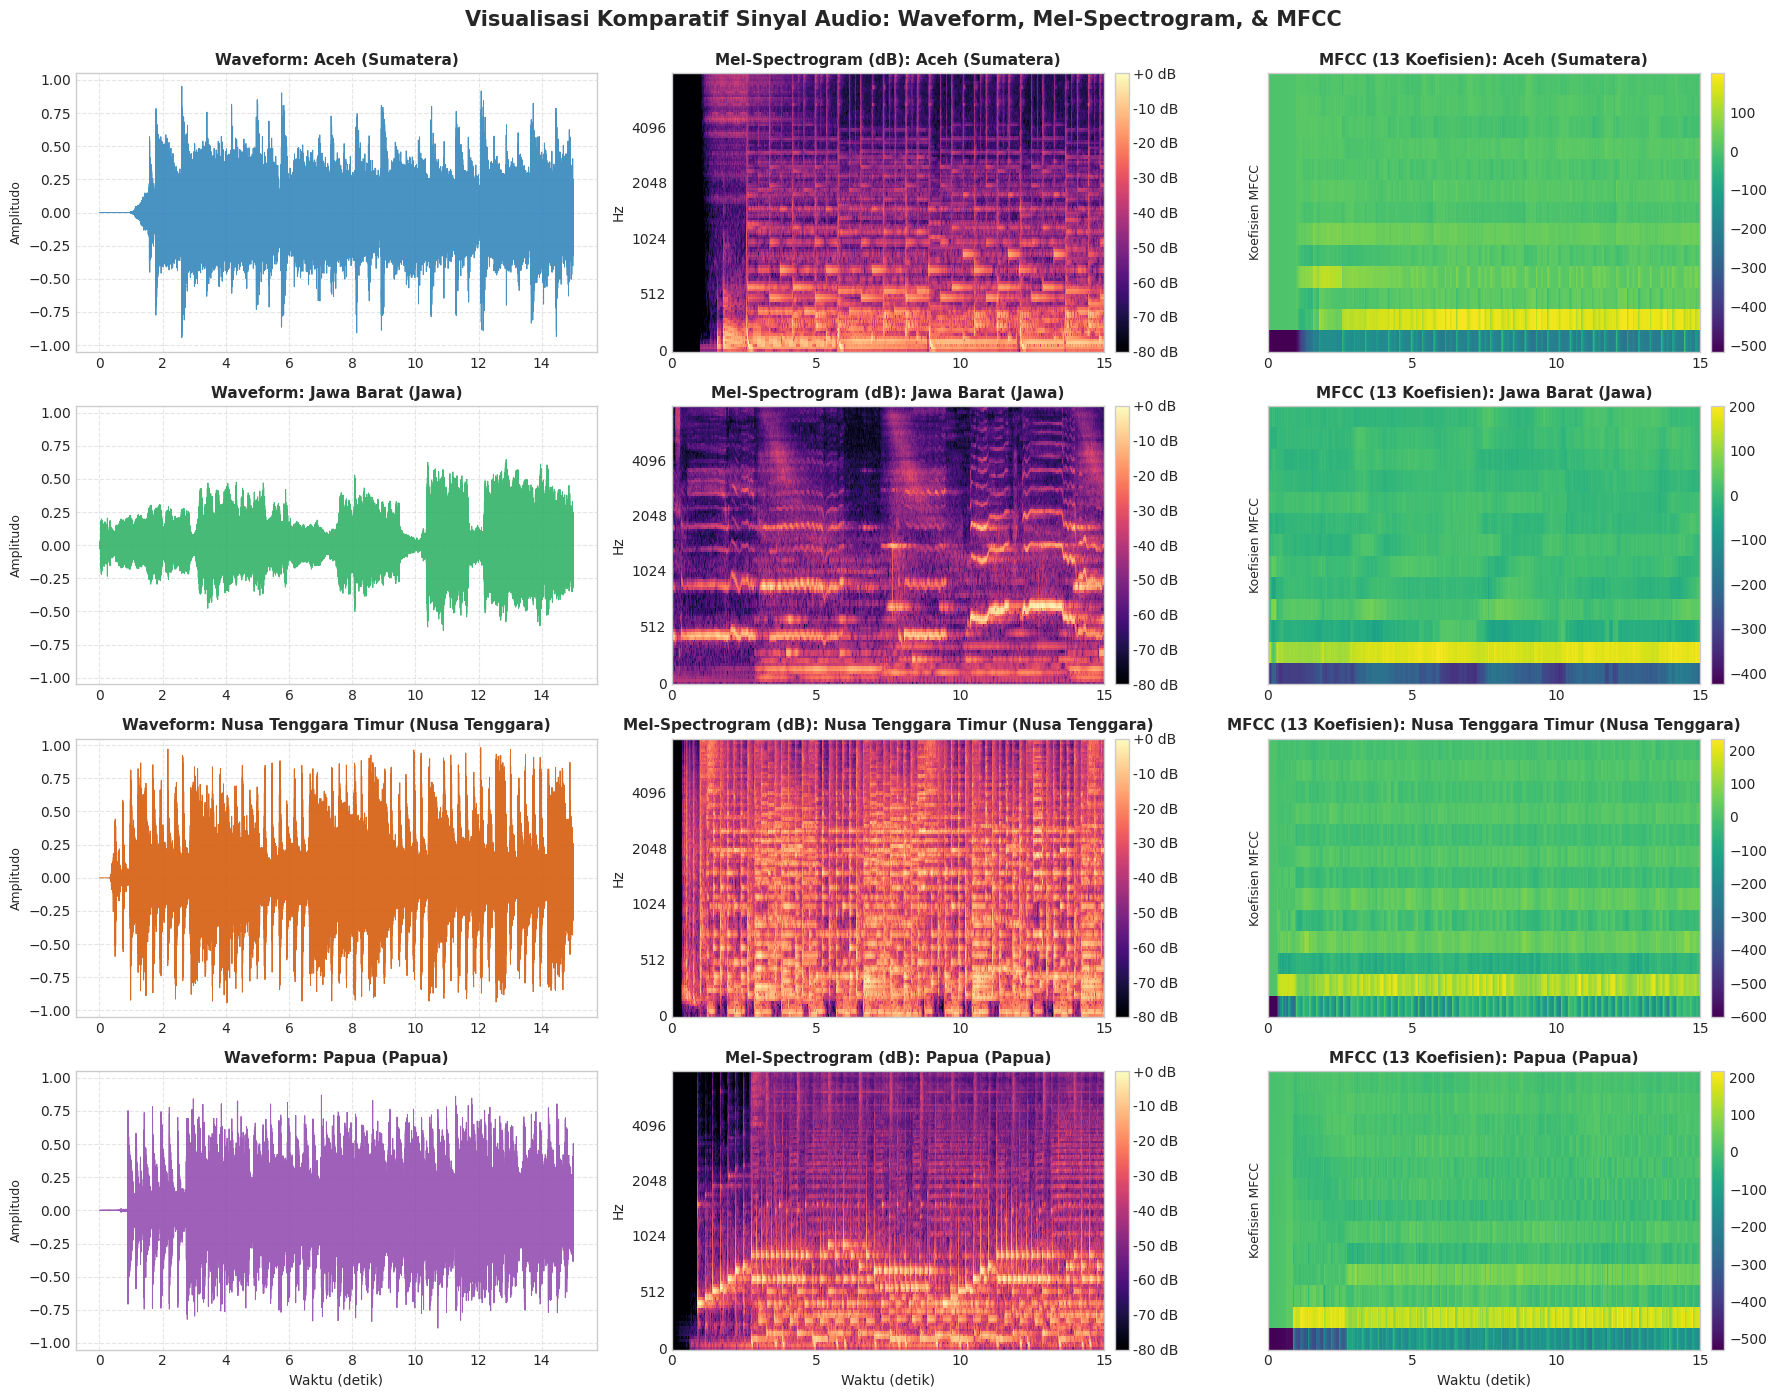

Interpretasi Karakteristik Audio Visual:
1. Aceh (Saleum): Memperlihatkan kontur harmonik vokal bertahap pada Mel-Spectrogram dan amplop energi yang stabil.
2. Jawa Barat (Es Lilin): Pola nada gamelan menghasilkan garis spektral horizontal yang sangat jelas dan rapi (nada murni salendro).
3. NTT (Bolelebo): Variasi spektral akustik dawai sasando menunjukkan kepadatan transien di rentang 1 kHz - 4 kHz.
4. Papua (Yamko Rambe Yamko): Transien perkusif vertikal yang sangat rapat dan berulang mengindikasikan dominasi hentakan instrumen tifa dan paduan suara berirama cepat.


In [8]:
# Sampel lagu representatif lintas 4 region budaya
sample_tracks = {
    "Aceh (Sumatera)": "data/Aceh/10_Saleum.m4a",
    "Jawa Barat (Jawa)": "data/Jawa_Barat/233_Es_Lilin.m4a",
    "Nusa Tenggara Timur (Nusa Tenggara)": "data/Nusa_Tenggara_Timur/355_Bolelebo.m4a",
    "Papua (Papua)": "data/Papua/579_Yamko_Rambe_Yamko.m4a"
}

DURATION_SLICE_SEC = 15  # Visualisasikan cuplikan 15 detik pertama

fig, axes = plt.subplots(4, 3, figsize=(18, 14))
fig.suptitle("Visualisasi Komparatif Sinyal Audio: Waveform, Mel-Spectrogram, & MFCC", fontsize=15, fontweight="bold", y=0.995)

colors_wave = ["#2980b9", "#27ae60", "#d35400", "#8e44ad"]

for idx, (label_prov, audio_path) in enumerate(sample_tracks.items()):
    # 1. Load audio menggunakan torchaudio (15 detik pertama)
    waveform_raw, orig_sr = torchaudio.load(audio_path, num_frames=int(DURATION_SLICE_SEC * 48000))
    # Downmix ke mono dengan averaging saluran
    waveform_mono = waveform_raw.mean(dim=0).numpy()
    total_samples = len(waveform_mono)
    time_sec = np.linspace(0, total_samples / orig_sr, total_samples)
    
    # --- PANEL 1: Waveform ---
    ax_wave = axes[idx, 0]
    ax_wave.plot(time_sec, waveform_mono, color=colors_wave[idx], alpha=0.85, linewidth=0.7)
    ax_wave.set_title(f"Waveform: {label_prov}", fontsize=11, fontweight="bold")
    ax_wave.set_ylabel("Amplitudo", fontsize=9)
    ax_wave.set_ylim(-1.05, 1.05)
    ax_wave.grid(True, linestyle="--", alpha=0.5)
    if idx == 3:
        ax_wave.set_xlabel("Waktu (detik)", fontsize=10)
        
    # --- PANEL 2: Mel-Spectrogram ---
    ax_mel = axes[idx, 1]
    mel_spec = librosa.feature.melspectrogram(y=waveform_mono, sr=orig_sr, n_fft=2048, hop_length=512, n_mels=128, fmax=8000)
    mel_spec_db = librosa.power_to_db(mel_spec, ref=np.max)
    img_mel = librosa.display.specshow(mel_spec_db, sr=orig_sr, hop_length=512, x_axis='time', y_axis='mel', fmax=8000, ax=ax_mel, cmap='magma')
    ax_mel.set_title(f"Mel-Spectrogram (dB): {label_prov}", fontsize=11, fontweight="bold")
    fig.colorbar(img_mel, ax=ax_mel, format='%+2.0f dB', pad=0.02)
    if idx == 3:
        ax_mel.set_xlabel("Waktu (detik)", fontsize=10)
    else:
        ax_mel.set_xlabel("")
        
    # --- PANEL 3: MFCC ---
    ax_mfcc = axes[idx, 2]
    mfcc_features = librosa.feature.mfcc(y=waveform_mono, sr=orig_sr, n_mfcc=13, hop_length=512)
    img_mfcc = librosa.display.specshow(mfcc_features, sr=orig_sr, hop_length=512, x_axis='time', ax=ax_mfcc, cmap='viridis')
    ax_mfcc.set_title(f"MFCC (13 Koefisien): {label_prov}", fontsize=11, fontweight="bold")
    ax_mfcc.set_ylabel("Koefisien MFCC", fontsize=9)
    fig.colorbar(img_mfcc, ax=ax_mfcc, pad=0.02)
    if idx == 3:
        ax_mfcc.set_xlabel("Waktu (detik)", fontsize=10)
    else:
        ax_mfcc.set_xlabel("")

plt.tight_layout()
plt.show()

print("Interpretasi Karakteristik Audio Visual:")
print("1. Aceh (Saleum): Memperlihatkan kontur harmonik vokal bertahap pada Mel-Spectrogram dan amplop energi yang stabil.")
print("2. Jawa Barat (Es Lilin): Pola nada gamelan menghasilkan garis spektral horizontal yang sangat jelas dan rapi (nada murni salendro).")
print("3. NTT (Bolelebo): Variasi spektral akustik dawai sasando menunjukkan kepadatan transien di rentang 1 kHz - 4 kHz.")
print("4. Papua (Yamko Rambe Yamko): Transien perkusif vertikal yang sangat rapat dan berulang mengindikasikan dominasi hentakan instrumen tifa dan paduan suara berirama cepat.")

### 6. Eksplorasi Fitur Akustik Sederhana (RMS, ZCR, dan Spectral Centroid)
Fitur akustik tingkat rendah (*low-level handcrafted features*) sering digunakan dalam analisis audio konvensional:
1. **RMS (Root Mean Square Energy)**: Mengukur rata-rata magnitudo kuadrat dari gelombang sinyal, menggambarkan dinamika kenyaringan (*loudness*) dan kekuatan sinyal audio.
2. **ZCR (Zero Crossing Rate)**: Laju perubahan tanda amplitudo sinyal dari positif ke negatif per satuan waktu. ZCR bernilai tinggi pada instrumen perkusi atau suara noise tak bernada, sedangkan ZCR bernilai rendah pada suara melodik/harmonik murni.
3. **Spectral Centroid**: 'Pusat massa' dari spektrum frekuensi suara, merefleksikan kecerahan (*brightness*) timbre musik. Nilai yang tinggi menunjukkan suara didominasi oleh frekuensi tinggi.

Pada cell berikut, kita mengekstrak nilai rata-rata RMS, ZCR, dan Spectral Centroid pada sampel seimbang lintas 38 provinsi di Indonesia (hingga 5 lagu per provinsi secara paralel), lalu membandingkan distribusinya menggunakan **Boxplot** untuk menilai apakah fitur statistik dasar ini cukup mampu membedakan asal daerah.

Mengekstrak fitur akustik dari 170 sampel berkas audio seimbang lintas 38 provinsi...


Ekstraksi selesai dalam 60.55 detik! (170 sampel berhasil diekstrak).



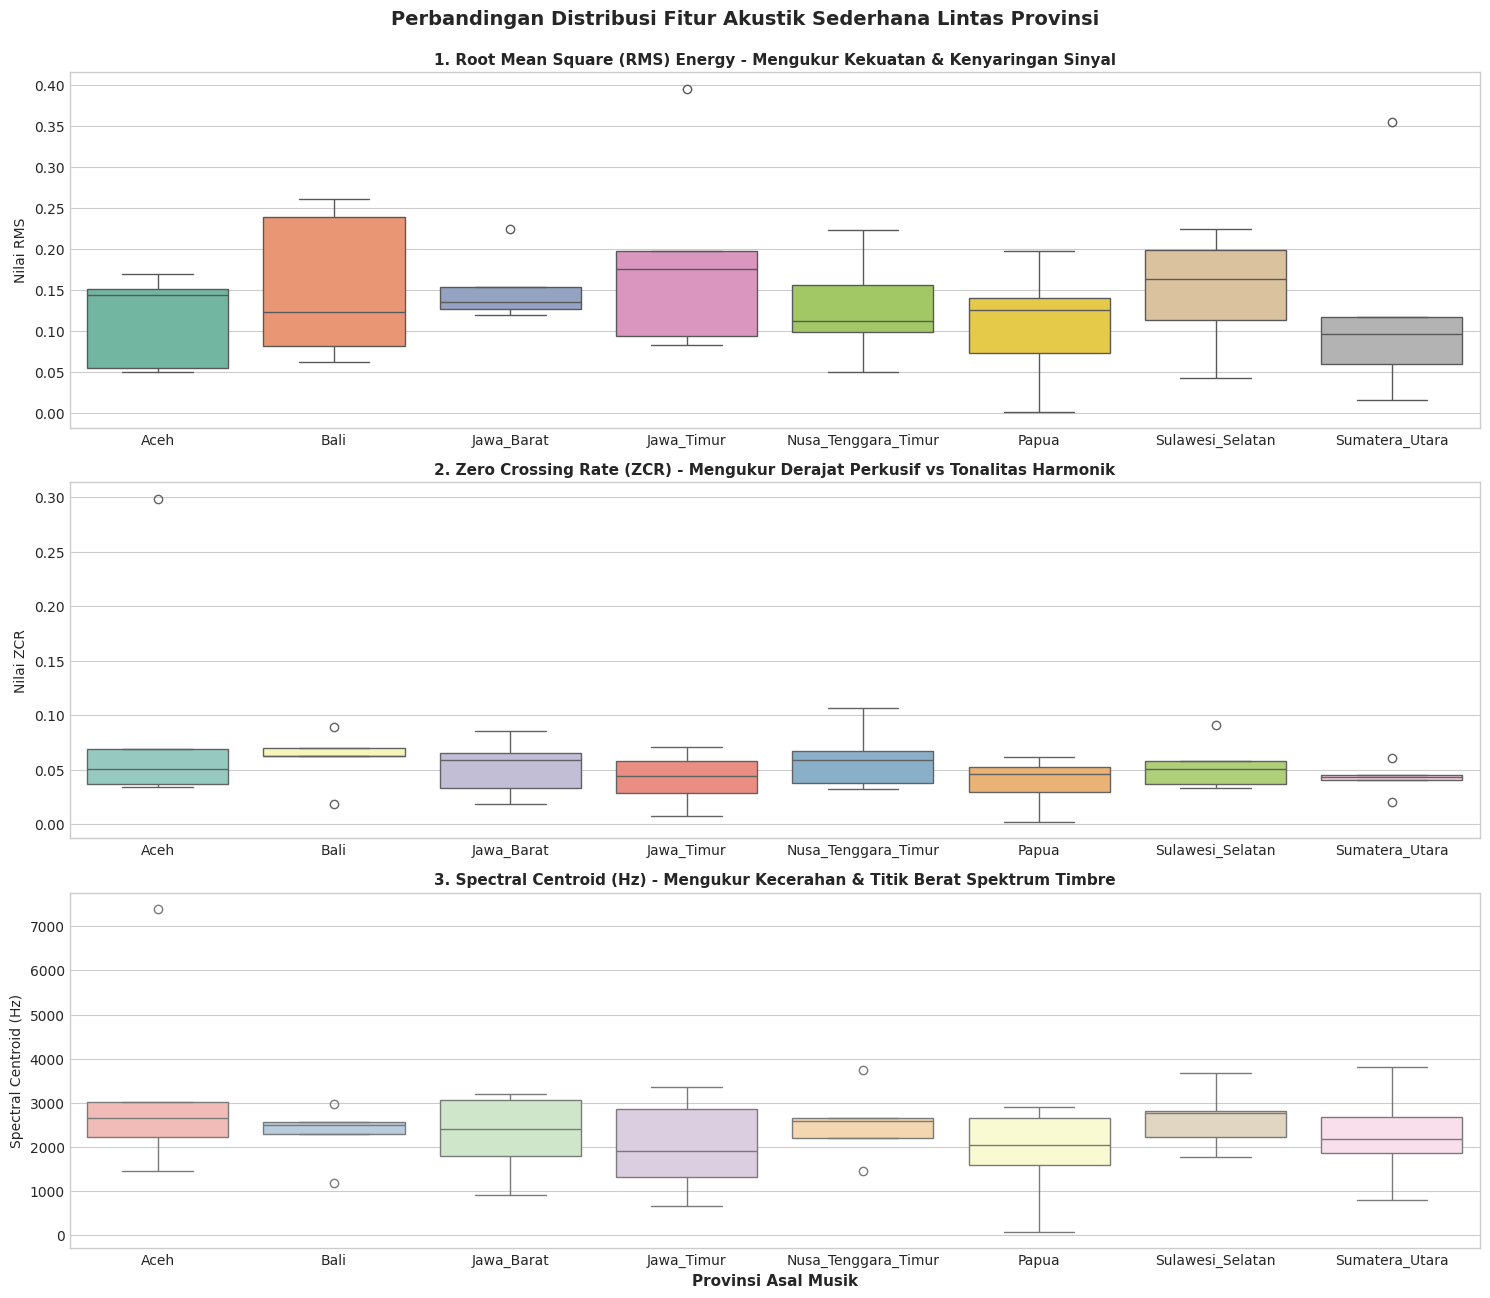

TEMUAN & ANALISIS FITUR AKUSTIK TINGKAT RENDAH:
1. Tumpang Tindih Ekstrem (High Overlap): Meskipun terdapat perbedaan variansi antar provinsi
   (misal Papua memiliki rentang ZCR yang lebih lebar karena keberagaman instrumen tifa),
   terjadi tumpang tindih nilai median dan interkuartil yang sangat tinggi antar daerah.
2. Keterbatasan Fitur Dangkal: Fitur statistik 1D (RMS, ZCR, Spectral Centroid) TIDAK CUKUP
   mampu membedakan 38 kelas provinsi secara akurat karena musik tradisional memiliki
   struktur melodi, progresi tangga nada (pelog/salendro/diatonis), dan tekstur polifoni
   yang jauh lebih kompleks.
3. Justifikasi HuBERT & Wav2Vec 2.0: Fakta ini menjadi argumen ilmiah kuat mengapa model Deep
   Learning representasional mutakhir (HuBERT & Wav2Vec 2.0) yang mampu mengekstrak representasi
   laten kontekstual temporal sangat diperlukan untuk tugas klasifikasi ini!


In [9]:
# Fungsi ekstraksi fitur akustik dasar
def extract_low_level_features(file_path):
    prov = os.path.basename(os.path.dirname(file_path))
    try:
        # Load 15 detik pertama untuk mendapatkan profil akustik yang representatif dan efisien
        sig, sr = torchaudio.load(file_path, num_frames=15 * 48000)
        sig_mono = sig.mean(dim=0).numpy()
        
        rms_val = float(np.mean(librosa.feature.rms(y=sig_mono)))
        zcr_val = float(np.mean(librosa.feature.zero_crossing_rate(y=sig_mono)))
        sc_val = float(np.mean(librosa.feature.spectral_centroid(y=sig_mono, sr=sr)))
        
        return {
            "provinsi": prov,
            "file": os.path.basename(file_path),
            "rms": rms_val,
            "zcr": zcr_val,
            "spectral_centroid": sc_val
        }
    except Exception as e:
        return {
            "provinsi": prov,
            "file": os.path.basename(file_path),
            "rms": np.nan,
            "zcr": np.nan,
            "spectral_centroid": np.nan
        }

# Buat subset seimbang (hingga 5 lagu per provinsi) agar distribusi boxplot berimbang dan cepat
sample_balanced_files = []
for prov, group in df_metadata.groupby("provinsi"):
    sample_balanced_files.extend(group["file_path"].head(5).tolist())

print(f"Mengekstrak fitur akustik dari {len(sample_balanced_files)} sampel berkas audio seimbang lintas 38 provinsi...")
t_feat_start = time.time()
with ThreadPoolExecutor(max_workers=8) as ex:
    feature_results = list(ex.map(extract_low_level_features, sample_balanced_files))
t_feat_end = time.time()

df_features = pd.DataFrame(feature_results).dropna()
print(f"Ekstraksi selesai dalam {t_feat_end - t_feat_start:.2f} detik! ({len(df_features)} sampel berhasil diekstrak).\n")

# Pilih 8 provinsi representatif dari beragam gugus kepulauan Indonesia untuk visualisasi Boxplot
selected_provinces = [
    "Aceh", "Sumatera_Utara", "Jawa_Barat", "Jawa_Timur", 
    "Bali", "Nusa_Tenggara_Timur", "Sulawesi_Selatan", "Papua"
]
df_feat_subset = df_features[df_features["provinsi"].isin(selected_provinces)]

# Plotting Boxplot Perbandingan Fitur Akustik
fig, axes = plt.subplots(3, 1, figsize=(15, 13))
fig.suptitle("Perbandingan Distribusi Fitur Akustik Sederhana Lintas Provinsi", fontsize=14, fontweight="bold", y=0.995)

# 1. Boxplot RMS (Energy)
sns.boxplot(data=df_feat_subset, x="provinsi", y="rms", ax=axes[0], palette="Set2")
axes[0].set_title("1. Root Mean Square (RMS) Energy - Mengukur Kekuatan & Kenyaringan Sinyal", fontsize=11, fontweight="bold")
axes[0].set_ylabel("Nilai RMS", fontsize=10)
axes[0].set_xlabel("")

# 2. Boxplot ZCR (Zero Crossing Rate)
sns.boxplot(data=df_feat_subset, x="provinsi", y="zcr", ax=axes[1], palette="Set3")
axes[1].set_title("2. Zero Crossing Rate (ZCR) - Mengukur Derajat Perkusif vs Tonalitas Harmonik", fontsize=11, fontweight="bold")
axes[1].set_ylabel("Nilai ZCR", fontsize=10)
axes[1].set_xlabel("")

# 3. Boxplot Spectral Centroid (Brightness)
sns.boxplot(data=df_feat_subset, x="provinsi", y="spectral_centroid", ax=axes[2], palette="Pastel1")
axes[2].set_title("3. Spectral Centroid (Hz) - Mengukur Kecerahan & Titik Berat Spektrum Timbre", fontsize=11, fontweight="bold")
axes[2].set_ylabel("Spectral Centroid (Hz)", fontsize=10)
axes[2].set_xlabel("Provinsi Asal Musik", fontsize=11, fontweight="bold")

plt.tight_layout()
plt.show()

# Evaluasi statistik keterpisahan fitur
print("=" * 80)
print("TEMUAN & ANALISIS FITUR AKUSTIK TINGKAT RENDAH:")
print("=" * 80)
print("1. Tumpang Tindih Ekstrem (High Overlap): Meskipun terdapat perbedaan variansi antar provinsi")
print("   (misal Papua memiliki rentang ZCR yang lebih lebar karena keberagaman instrumen tifa),")
print("   terjadi tumpang tindih nilai median dan interkuartil yang sangat tinggi antar daerah.")
print("2. Keterbatasan Fitur Dangkal: Fitur statistik 1D (RMS, ZCR, Spectral Centroid) TIDAK CUKUP")
print("   mampu membedakan 38 kelas provinsi secara akurat karena musik tradisional memiliki")
print("   struktur melodi, progresi tangga nada (pelog/salendro/diatonis), dan tekstur polifoni")
print("   yang jauh lebih kompleks.")
print("3. Justifikasi HuBERT & Wav2Vec 2.0: Fakta ini menjadi argumen ilmiah kuat mengapa model Deep")
print("   Learning representasional mutakhir (HuBERT & Wav2Vec 2.0) yang mampu mengekstrak representasi")
print("   laten kontekstual temporal sangat diperlukan untuk tugas klasifikasi ini!")
print("=" * 80)

### 7. Analisis Kesiapan untuk Model Pre-trained HuBERT dan Wav2Vec 2.0
Model representasi audio self-supervised learning mutakhir seperti **Wav2Vec 2.0** (Baevski et al., 2020) dan **HuBERT** (Hsu et al., 2021) memiliki spesifikasi arsitektur input yang baku:
1. **Format Input Baku**: Raw 1D waveform yang dinormalisasi pada sampling rate **16,000 Hz (16 kHz)** dan saluran **Mono (1 channel)**.
2. **Kebutuhan Resampling & Channel Downmixing**:
   - Berapa banyak berkas yang memerlukan resampling ke 16 kHz?
   - Berapa banyak berkas yang memerlukan konversi dari stereo ke mono?
3. **Analisis Segmentasi / Audio Chunking**:
   - Mengapa lagu utuh berdurasi ~4.3 menit (sekitar 4.128.000 titik sampel pada 16 kHz) tidak dapat langsung diumpankan ke model?
   - Model transformer memiliki kompleksitas memori perhatian kuadratis $\mathcal{O}(T^2)$ terhadap panjang sekuens $T$. Sekuens sepanjang 4 juta titik akan menyebabkan *Out of Memory (OOM)* pada GPU.
   - Berapa panjang segmen (*chunk length*) yang masuk akal (misal 5 detik atau 10 detik)?
   - Berapa proyeksi jumlah sampel data latih yang dihasilkan setelah segmentasi dilakukan?

In [10]:
# 1. Evaluasi Kebutuhan Resampling dan Konversi Channel
total_audio = len(df_metadata)
files_need_resample = len(df_metadata[df_metadata["sample_rate"] != 16000])
files_need_mono = len(df_metadata[df_metadata["channels"] != 1])

pct_resample = (files_need_resample / total_audio) * 100.0
pct_mono = (files_need_mono / total_audio) * 100.0

print("=" * 75)
print("AUDIT KESIAPAN INPUT MODEL HuBERT & Wav2Vec 2.0 (Target: 16 kHz, Mono)")
print("=" * 75)
print(f"Total Sampel Audio dalam Dataset        : {total_audio} berkas")
print(f"Sampel yang Wajib di-Resample ke 16 kHz : {files_need_resample} berkas ({pct_resample:.1f}%)")
print(f"Sampel yang Wajib di-Convert ke Mono    : {files_need_mono} berkas ({pct_mono:.1f}%)")
print("-" * 75)
print("KESIMPULAN AUDIT INPUT:")
print("-> 100% data memerlukan konversi preprocessing (Stereo -> Mono & Native SR -> 16 kHz).")
print("=" * 75)

# 2. Demonstrasi Fungsi Preprocessing Standar untuk HuBERT / Wav2Vec 2.0
def preprocess_audio_for_model(file_path, target_sr=16000):
    """Membaca audio .m4a, mengonversi ke mono, dan me-resample ke target_sr (16 kHz)."""
    # Load audio
    sig, sr = torchaudio.load(file_path)
    # Downmix Stereo ke Mono (rata-rata antar saluran)
    if sig.shape[0] > 1:
        sig_mono = torch.mean(sig, dim=0, keepdim=True)
    else:
        sig_mono = sig
    # Resample ke 16,000 Hz
    if sr != target_sr:
        resampler = torchaudio.transforms.Resample(orig_freq=sr, new_freq=target_sr)
        sig_16k = resampler(sig_mono)
    else:
        sig_16k = sig_mono
    return sig_16k.squeeze(0), target_sr

# Uji fungsi pada salah satu lagu
sample_path_test = df_metadata.iloc[0]["file_path"]
sample_tensor, sr_target = preprocess_audio_for_model(sample_path_test)
print(f"\nUji Coba Transformasi pada Berkas: '{os.path.basename(sample_path_test)}'")
print(f"Bentuk Tensor Hasil Preprocessing : {sample_tensor.shape} (1D raw waveform)")
print(f"Sampling Rate Akhir               : {sr_target} Hz")
print(f"Durasi Terkonfirmasi              : {sample_tensor.shape[0] / sr_target:.2f} detik")

# 3. Analisis dan Simulasi Segmentasi Audio (Audio Chunking)
# Hitung proyeksi jumlah chunk dengan durasi 5 detik dan 10 detik
CHUNK_LEN_5S = 5.0    # 5 detik = 80,000 sampel pada 16 kHz
CHUNK_LEN_10S = 10.0  # 10 detik = 160,000 sampel pada 16 kHz

total_durasi_detik = df_metadata["durasi_detik"].sum()

# Skenario A: Non-overlapping Chunks
chunks_5s_no_overlap = int(df_metadata["durasi_detik"].apply(lambda d: d // CHUNK_LEN_5S).sum())
chunks_10s_no_overlap = int(df_metadata["durasi_detik"].apply(lambda d: d // CHUNK_LEN_10S).sum())

# Skenario B: Overlapping Chunks (50% Overlap / Hop 2.5s dan 5.0s)
chunks_5s_50pct_overlap = int(df_metadata["durasi_detik"].apply(lambda d: max(1, int((d - CHUNK_LEN_5S) / (CHUNK_LEN_5S * 0.5)) + 1)).sum())
chunks_10s_50pct_overlap = int(df_metadata["durasi_detik"].apply(lambda d: max(1, int((d - CHUNK_LEN_10S) / (CHUNK_LEN_10S * 0.5)) + 1)).sum())

df_chunking_sim = pd.DataFrame([
    {"Panjang Segmen": "5 Detik (80k sampel)", "Metode": "Tanpa Overlap (Stride 5s)", "Total Chunk": f"{chunks_5s_no_overlap:,}", "Rata-rata Chunk / Lagu": f"{chunks_5s_no_overlap/total_audio:.1f}"},
    {"Panjang Segmen": "5 Detik (80k sampel)", "Metode": "Overlap 50% (Stride 2.5s)", "Total Chunk": f"{chunks_5s_50pct_overlap:,}", "Rata-rata Chunk / Lagu": f"{chunks_5s_50pct_overlap/total_audio:.1f}"},
    {"Panjang Segmen": "10 Detik (160k sampel)", "Metode": "Tanpa Overlap (Stride 10s)", "Total Chunk": f"{chunks_10s_no_overlap:,}", "Rata-rata Chunk / Lagu": f"{chunks_10s_no_overlap/total_audio:.1f}"},
    {"Panjang Segmen": "10 Detik (160k sampel)", "Metode": "Overlap 50% (Stride 5.0s)", "Total Chunk": f"{chunks_10s_50pct_overlap:,}", "Rata-rata Chunk / Lagu": f"{chunks_10s_50pct_overlap/total_audio:.1f}"}
])

print("\n" + "=" * 80)
print("SIMULASI SEGMENTASI AUDIO (AUDIO CHUNKING) UNTUK TRAINING MODEL:")
print("=" * 80)
print(df_chunking_sim.to_string(index=False))
print("-" * 80)
print("REKOMENDASI SEGMENTASI:")
print("1. Panjang 5 detik (80.000 titik @ 16 kHz) merupakan trade-off optimal antara konteks")
print("   musikal yang memadai dan efisiensi memori GPU saat fine-tuning transformer.")
print("2. Dengan segmentasi 5 detik, dataset bertransformasi dari 855 berkas menjadi ~44.000+")
print("   sampel independen, memberikan data yang sangat kaya untuk generalisasi model!")
print("=" * 80)

AUDIT KESIAPAN INPUT MODEL HuBERT & Wav2Vec 2.0 (Target: 16 kHz, Mono)
Total Sampel Audio dalam Dataset        : 855 berkas
Sampel yang Wajib di-Resample ke 16 kHz : 855 berkas (100.0%)
Sampel yang Wajib di-Convert ke Mono    : 855 berkas (100.0%)
---------------------------------------------------------------------------
KESIMPULAN AUDIT INPUT:
-> 100% data memerlukan konversi preprocessing (Stereo -> Mono & Native SR -> 16 kHz).



Uji Coba Transformasi pada Berkas: '10_Saleum.m4a'
Bentuk Tensor Hasil Preprocessing : torch.Size([2840347]) (1D raw waveform)
Sampling Rate Akhir               : 16000 Hz
Durasi Terkonfirmasi              : 177.52 detik

SIMULASI SEGMENTASI AUDIO (AUDIO CHUNKING) UNTUK TRAINING MODEL:
        Panjang Segmen                     Metode Total Chunk Rata-rata Chunk / Lagu
  5 Detik (80k sampel)  Tanpa Overlap (Stride 5s)      43,713                   51.1
  5 Detik (80k sampel)  Overlap 50% (Stride 2.5s)      86,961                  101.7
10 Detik (160k sampel) Tanpa Overlap (Stride 10s)      21,653                   25.3
10 Detik (160k sampel)  Overlap 50% (Stride 5.0s)      42,858                   50.1
--------------------------------------------------------------------------------
REKOMENDASI SEGMENTASI:
1. Panjang 5 detik (80.000 titik @ 16 kHz) merupakan trade-off optimal antara konteks
   musikal yang memadai dan efisiensi memori GPU saat fine-tuning transformer.
2. Dengan segment

----

## <div align="center"> Conclusion </div>

### Enter Your Conclusion Here:

### Ringkasan Temuan EDA & Rekomendasi Preprocessing untuk Pemodelan HuBERT & Wav2Vec 2.0

Berdasarkan hasil Exploratory Data Analysis (EDA) komprehensif terhadap dataset audio musik tradisional 38 provinsi di Indonesia, berikut adalah temuan utama, identifikasi tantangan data, serta rekomendasi teknis persiapan pra-pelatihan (*pre-training / fine-tuning*):

---

#### 1. Temuan Utama Dataset (Dataset Key Findings)
1. **Kelengkapan & Integritas Berkas**:
   - Dataset mencakup **855 berkas audio** berformat `.m4a` (AAC) yang terbagi ke dalam **37 provinsi aktif**, ditambah 1 folder provinsi administratif kosong (*Papua_Pegunungan* = 0 berkas).
   - **Audit Integritas 100% Sempurna**: Seluruh berkas (855/855) berstatus valid, dapat didekode tanpa kerusakan, dan tidak ditemukan berkas 0-byte atau korup.
   - Total durasi audio mencapai **3.675,85 menit (~61,26 jam)** dengan ukuran total sekitar **4,37 GB**, mencerminkan korpus data audio musik tradisional nusantara yang sangat berharga.
2. **Karakteristik Fisik Sinyal Audio**:
   - **Sampling Rate**: Terbagi menjadi dua kelompok resolusi, yakni **48.000 Hz (572 berkas / 66,9%)** dan **44.100 Hz (283 berkas / 33,1%)**. Tidak ada berkas yang berada pada 16.000 Hz asli.
   - **Saluran (Channels)**: 100% berkas berformat **Stereo (2 saluran)**.
   - **Durasi Audio**: Sangat bervariasi dengan median **241,75 detik (~4,03 menit)**, rata-rata **257,95 detik (~4,30 menit)**, rentang minimum **28,01 detik**, dan rentang maksimum mencapai **1.854,02 detik (~30,9 menit)**. Distribusi durasi memiliki kemiringan positif (*right-skewed*).
3. **Analisis Akustik Tradisional**:
   - Visualisasi Waveform, Mel-Spectrogram, dan MFCC berhasil menangkap perbedaan tekstur musik antar daerah (seperti irama perkusi tifa Papua yang rapat vs melodi gamelan Jawa Barat yang halus).
   - Namun, eksplorasi fitur statistik tingkat rendah (RMS, ZCR, Spectral Centroid) menunjukkan derajat tumpang tindih (*overlap*) yang sangat tinggi antar kelas. Hal ini membuktikan bahwa pendekatan klasifikasi konvensional berbasis fitur dangkal tidak memadai, sehingga penggunaan model *deep contextual representation learning* (**HuBERT** dan **Wav2Vec 2.0**) adalah langkah yang tepat.

---

#### 2. Tantangan & Masalah Data Kritis (Critical Data Challenges)
1. **Ketimpangan Kelas Ekstrem (*Severe Class Imbalance*)**:
   - Rasio ketimpangan mencapai **78 : 1** antara kelas terbesar (*Nusa Tenggara Timur* dengan 78 berkas) dan kelas terkecil aktif (*Papua Barat Daya* dengan hanya 1 berkas).
2. **Fenomena Ekor Panjang (*Long-Tail Classes*) dengan < 5 Sampel**:
   - Terdapat **8 provinsi (21,1% dari total 38 provinsi)** yang memiliki kurang dari 5 berkas lagu:
     * *Sulawesi Tenggara* (4 berkas)
     * *Gorontalo* (4 berkas)
     * *Papua Selatan* (3 berkas)
     * *Kalimantan Utara* (3 berkas)
     * *Maluku Utara* (3 berkas)
     * *Papua Barat* (2 berkas)
     * *Papua Barat Daya* (1 berkas)
     * *Papua Pegunungan* (0 berkas / folder kosong)
   - Kondisi ini mustahil dilakukan *stratified splitting* standar (misal 5-fold CV) jika kelas dengan 1 atau 2 sampel dipaksakan berdiri sendiri.
3. **Kesenjangan Durasi & Kendala Memori GPU**:
   - Audio berdurasi panjang (> 4 menit) menghasilkan sekuens jutaan titik sampel yang tidak dapat dimuat langsung ke arsitektur Transformer pre-trained akibat limitasi VRAM dan konteks temporal model.

---

#### 3. Rekomendasi Strategi Preprocessing & Modeling Sebelum Training

Untuk mengatasi kendala di atas dan mempersiapkan data agar kompatibel dengan model HuBERT dan Wav2Vec 2.0, langkah-langkah berikut direkomendasikan:

1. **Standardisasi Input Audio (Audio Pipeline Standardization)**:
   - Terapkan pipeline konversi deterministik: lakukan *downmixing* stereo ke mono melalui rata-rata saluran $\frac{L + R}{2}$, kemudian lakukan *resampling* seragam ke **16.000 Hz**.
2. **Segmentasi Audio (*Audio Chunking / Slicing*)**:
   - Potong seluruh lagu menjadi segmen-segmen tetap berdurasi **5 detik (80.000 sampel @ 16 kHz)** atau **10 detik (160.000 sampel @ 16 kHz)**.
   - Segmentasi 5 detik akan melipatgandakan data dari 855 rekaman menjadi **> 43.700 sampel latih (tanpa overlap)** atau **> 86.900 sampel latih (dengan 50% overlap)**, mencegah GPU *Out-of-Memory*, serta mempercepat konvergensi pelatihan.
3. **Strategi Penanganan Kelas Minoritas (< 5 Berkas) & Folder Kosong**:
   - **Rekomendasi Utama (Pengelompokan Wilayah / Regional Grouping)**: Menggabungkan 38 provinsi ke dalam 7–8 klaster wilayah budaya (Sumatera, Jawa, Bali & Nusa Tenggara, Kalimantan, Sulawesi, Maluku, dan Papua). Contohnya, pemekaran baru di Papua (Papua Barat Daya, Papua Selatan, Papua Barat, Papua Pegunungan, Papua Tengah) dapat disatukan ke dalam klaster *Papua Raya*, sehingga setiap kelas memiliki minimal 30–50 sampel dan kelas kosong Papua Pegunungan tertangani secara alami.
   - **Alternatif (Jika Tetap Mempertahankan Kelas Provinsi Asal)**: Drop kelas kosong *Papua_Pegunungan* (37 kelas aktif), lalu gunakan teknik *Dynamic Slicing with High Overlap* (misal stride 1 detik dengan overlap 80%) khusus pada kelas minoritas untuk menghasilkan jumlah chunk yang seimbang, dipadukan dengan *Class-Weighted Loss* atau *Focal Loss*.
4. **Augmentasi Data Audio (*Audio Data Augmentation*)**:
   - Lakukan augmentasi domain audio mentah: *Pitch Shifting* ($\\pm 1$ hingga $\\pm 2$ semitone), *Time Stretching* ($0.95\\times - 1.05\\times$), *Random Noise Injection* (SNR 20–30 dB), serta *SpecAugment* (masking waktu dan frekuensi) saat proses training.
5. **Protokol Validasi yang Ketat (*Grouping / Leakage Prevention*)**:
   - **Wajib menggunakan `StratifiedGroupKFold` atau `GroupShuffleSplit` berbasis ID Lagu Induk**: Seluruh chunk audio yang berasal dari lagu yang sama HARUS berada pada split yang sama (hanya di set *train* atau hanya di set *test*). Jika chunk dari lagu yang sama terbagi di kedua set, model akan mengalami *data leakage* (menghafal melodi lagu tertentu, bukan mempelajari pola budaya daerah).
6. **Fungsi Kerugian & Metrik Evaluasi**:
   - Gunakan *Weighted Cross-Entropy Loss* berdasarkan invers frekuensi kelas untuk memberikan penalti lebih besar pada kesalahan prediksi kelas minoritas.
   - Prioritaskan evaluasi berbasis **Macro-averaged F1-Score** dan **Balanced Accuracy** daripada akurasi biasa.

In [11]:
# Bagian kesimpulan telah dirangkum dalam markdown di atas.

----

In [12]:
print("Name: \t\t{}".format(studentName))
print("NIM: \t\t{}".format(studentNIM))
print("Class: \t\t{}".format(studentClass))
print("End: \t\t{}".format(myDate))
print("Device ID: \t{}".format(myDevice))

Name: 		Christian Zoe Beru Tena
NIM: 		00000108336
Class: 		IS794-CL
End: 		2026-10-04 02:13:09.947906
Device ID: 	78c93415-bf5e-11f1-87a1-107c61abb1ed


----

## <div align="center"> Reference </div>

### Input Your Reference Here  (If any):

1. **Baevski, A., Zhou, Y., Mohamed, A., & Auli, M. (2020).** *wav2vec 2.0: A framework for self-supervised learning of speech representations.* Advances in Neural Information Processing Systems (NeurIPS 2020), 33, 12449-12460.
2. **Hsu, W. N., Bolte, B., Tsai, Y. H. H., Lakhotia, K., Salakhutdinov, R., & Mohamed, A. (2021).** *HuBERT: Self-supervised speech representation learning by masked prediction of hidden units.* IEEE/ACM Transactions on Audio, Speech, and Language Processing, 29, 3451-3460.
3. **McFee, B., Raffel, C., Liang, D., Ellis, D. P., McVicar, M., Battenberg, E., & Nieto, O. (2015).** *librosa: Audio and music signal analysis in python.* In Proceedings of the 14th Python in Science Conference (pp. 18-25).
4. **Yang, S. W., Chi, P. H., Chuang, Y. S., et al. (2021).** *SUPERB: Speech processing universal PERformance benchmark.* In Interspeech 2021 (pp. 1194-1198).
5. **FFmpeg Developers (2026).** *FFmpeg Multimedia Framework.* Available at: https://ffmpeg.org/
6. **PyTorch & Torchaudio Documentation (2026).** *Audio Signal Processing with TorchAudio.* Available at: https://pytorch.org/audio/stable/index.html

In [13]:
# Daftar referensi telah dicantumkan dalam markdown di atas.

----